<a href="https://colab.research.google.com/github/PDM-15/AML-2026/blob/master/AML_Lab8/ML_Lab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Wrapper methods

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

data = load_breast_cancer()
X = data.data
y = data.target

In [ ]:
print(X.shape)

(569, 30)


Forward Feature Selection

In [ ]:
model = Pipeline([("scaler", StandardScaler()), ("selector", LogisticRegression(max_iter=5000))])
selector = SequentialFeatureSelector(model, n_features_to_select=5, direction="forward", scoring="accuracy", cv=5)
selector.fit(X, y)
print(data.feature_names[selector.get_support()])

['mean symmetry' 'concavity error' 'worst texture' 'worst perimeter'
 'worst smoothness']


Backward Feature Selection

In [ ]:
selector = SequentialFeatureSelector(model, n_features_to_select=5, direction="backward", scoring="accuracy", cv=5)
selector.fit(X, y)
print(data.feature_names[selector.get_support()])

['mean texture' 'mean concave points' 'worst area' 'worst smoothness'
 'worst concavity']


Recursive Feature Elimination

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

data = load_breast_cancer()
X = data.data
y = data.target

X_scaled = StandardScaler().fit_transform(X)

model = LogisticRegression(max_iter=5000)

selector = RFE(estimator = model, n_features_to_select=5, step=1) #removing one feature at a time

selector.fit(X_scaled,y)

for name, selected, rank in zip(data.feature_names, selector.support_, selector.ranking_):#RFE rank for each feature
    print(name,selected,rank)


mean radius False 12
mean texture False 14
mean perimeter False 15
mean area False 8
mean smoothness False 23
mean compactness False 10
mean concavity False 13
mean concave points False 3
mean symmetry False 25
mean fractal dimension False 20
radius error True 1
texture error False 22
perimeter error False 9
area error False 4
smoothness error False 18
compactness error False 6
concavity error False 24
concave points error False 21
symmetry error False 17
fractal dimension error False 16
worst radius True 1
worst texture True 1
worst perimeter False 2
worst area True 1
worst smoothness False 7
worst compactness False 26
worst concavity False 5
worst concave points True 1
worst symmetry False 11
worst fractal dimension False 19


RFECV

In [ ]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

model = LogisticRegression(max_iter=5000)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

selector = RFECV(estimator = model, step=1, cv=cv, scoring="accuracy", min_features_to_select=1)

selector.fit(X_scaled,y)

print("Optimal number of features:", selector.n_features_)
print("Selected features:", data.feature_names[selector.support_])

Optimal number of features: 23
Selected features: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean compactness' 'mean concavity' 'mean concave points' 'radius error'
 'perimeter error' 'area error' 'smoothness error' 'compactness error'
 'symmetry error' 'fractal dimension error' 'worst radius' 'worst texture'
 'worst perimeter' 'worst area' 'worst smoothness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


Embedded Methods

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lasso = LassoCV(cv=5, random_state = 42, max_iter = 10000)
lasso.fit(X_scaled, y)
coefficients = pd.Series(lasso.coef_, index = X.columns)

selected_features = coefficients[coefficients.abs()>1e-6]

print("Best alpha:", lasso.alpha_)
print("Selected Features:\n", selected_features)

Best alpha: 0.07891843500595844
Selected Features:
 age    -0.308921
sex   -11.225046
bmi    24.816849
bp     15.271304
s1    -27.085410
s2     14.386231
s4      6.835041
s5     31.864972
s6      3.179041
dtype: float64


L1 regularised logistic regression

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data
y = data.target

pipeline = Pipeline([("scaler", StandardScaler()), ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=0.1, max_iter=5000))), ("classification", LogisticRegression(max_iter=5000))])

pipeline.fit(X,y)
mask= pipeline.named_steps["selection"].get_support()

print(data.feature_names[mask])

['mean concave points' 'radius error' 'worst radius' 'worst texture'
 'worst smoothness' 'worst concavity' 'worst concave points'
 'worst symmetry']


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn. feature_selection import SelectFromModel

iris = load_iris()
X, y = iris.data, iris.target

clf = RandomForestClassifier(n_estimators=10)
clf = clf.fit(X,y)
clf.feature_importances_

model = SelectFromModel(clf, prefit = True)
X_new = model.transform()

array([0.12678834, 0.02070318, 0.48182717, 0.37068131])

Feature Selection using pipeline

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
clfs = Pipeline([('feature_selection', SelectFromModel(RandomForestClassifier(n_estimators=10))), ('classification', KNeighborsClassifier())])

model = clfs.fit(X, y)
model

Pipeline(steps=[('feature_selection',
                 SelectFromModel(estimator=RandomForestClassifier(n_estimators=10))),
                ('classification', KNeighborsClassifier())])

Logistic Regression

In [ ]:
import pandas as pd

data = {"study_hours":[1,2,2,3,4,5,6,7,8,9],
        "Attendance": [50,55,60,65,70,75,75, 80,90,95],
        "Pass": [0,0,0,0,0,1,1,1,1,1]}

df = pd.DataFrame(data)

X = df[["study_hours", "Attendance"]]
y = df["Pass"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify = y, random_state=42)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression()
model.fit(X_train_scaled, y_train)


LogisticRegression()

In [ ]:
y_pred = model.predict(X_test_scaled)
y_probability = model.predict_proba(X_test_scaled)

print("Predicted classes:", y_test)
print("Class probabilities:", y_probability)

Predicted classes: 0    0
3    0
9    1
Name: Pass, dtype: int64
Class probabilities: [[0.94123215 0.05876785]
 [0.70346615 0.29653385]
 [0.02194839 0.97805161]]


In [ ]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: [0.42610721]
Coefficients: [[0.91130326 0.78163544]]


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Confusion Matrix:
 [[2 0]
 [0 1]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



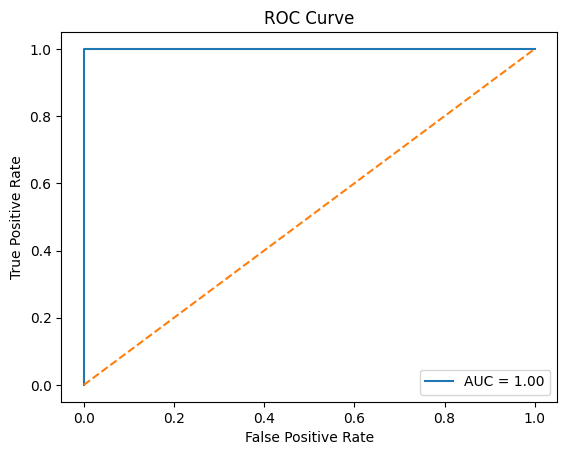

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

prob_positive = model.predict_proba(X_test_scaled)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, prob_positive)
auc_value = roc_auc_score(y_test, prob_positive)

plt.plot(fpr, tpr, label = f"AUC = {auc_value:.2f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Assignment

Logistic Regression and ROC AUC Curve

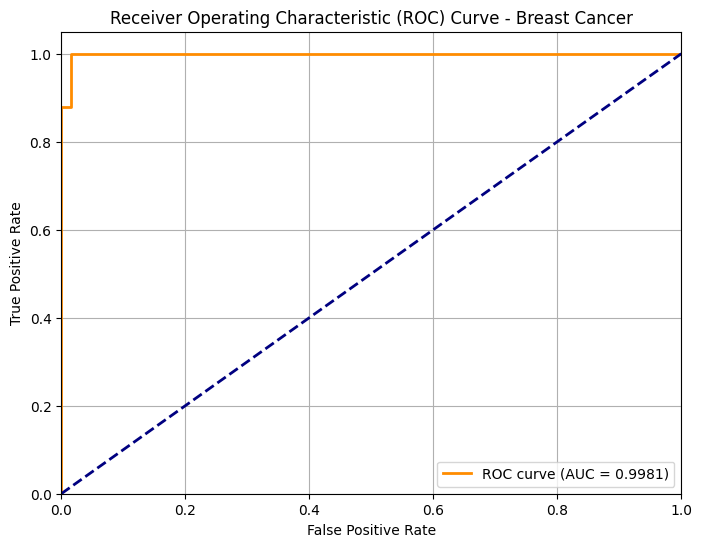

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Load dataset
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression model
log_reg = LogisticRegression(max_iter=5000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Predict probabilities for the positive class
y_probs = log_reg.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC metrics
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc_score = roc_auc_score(y_test, y_probs)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Breast Cancer')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()